<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab_9SOTAipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №9: Fine-tuning VLM с помощью LLaMA-Factory

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Преобразовать мультимодальные данные в instruction format.
- Сформировать QLoRA YAML и запустить SFT.
- Сравнить base и adapter, включая OOD slice.


## Теоретическая часть

SFT минимизирует autoregressive loss только на целевом ответе. QLoRA хранит base weights в 4-bit NF4 и обучает low-rank update $\Delta W=BA$, что уменьшает память. LLaMA-Factory фиксирует pipeline в YAML-конфигурации.


### Математическая постановка

$$W'=W_q+\frac{\alpha}{r}BA,\quad B\in\mathbb R^{d\times r},\ A\in\mathbb R^{r\times k}.$$ Обучаются только $A,B$; сравнение проводится с той же base model и evaluation set.


### Материалы

- [LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)
- [QLoRA](https://arxiv.org/abs/2305.14314)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Вход — лицензированный предметный корпус `data/lab9/manifest.jsonl` с независимыми train/validation/ID/OOD. Получение и экспертная проверка данных обязательны; файл не заменяется выдуманным изображением. В Colab установите совместимый LLaMA-Factory из зафиксированного commit и запишите commit в отчёт. CLI запускается непосредственно из ноутбука. Полный режим означает фактическое обучение и сравнение; `FAST_DEV_RUN` обучает два шага только для проверки стека. Оценку общей способности выполните на отдельном общем VQA-наборе с заранее выбранной метрикой.

In [ ]:
from pathlib import Path
import json, os, random, time, hashlib
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
# монтируем Google Drive и определяем ARTIFACTS / DATA_ROOT
IN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    DRIVE_ROOT = Path("/content/drive/MyDrive/cv_lab9")
except Exception:
    # Локальный запуск вне Colab (или Drive недоступен)
    DRIVE_ROOT = Path(os.getenv("CV_LAB9_ROOT", "cv_lab9"))

# Артефакты (адаптер, логи, предсказания, метрики)
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", DRIVE_ROOT / "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Данные (манифест + скачанные изображения ScienceQA)
# иначе повторная загрузка при каждом перезапуске сессии
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA", DRIVE_ROOT / "data"))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

LAB9_DATA_DIR = DATA_ROOT / "lab9"
LAB9_DATA_DIR.mkdir(parents=True, exist_ok=True)

# сиды и устройство
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"

# утилита сохранения JSON
def save_json(name, data):
    (ARTIFACTS / name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

# подготовка манифеста ScienceQA
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest

# запуск: данные и манифест
manifest_path = prepare_scienceqa(LAB9_DATA_DIR, smoke=FAST_DEV_RUN)

# диагностика окружения
gpu_info = None
if torch is not None and torch.cuda.is_available():
    gpu_info = {
        "name": torch.cuda.get_device_name(0),
        "total_memory_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
    }

print(json.dumps({
    "in_colab": IN_COLAB,
    "device": DEVICE,
    "gpu": gpu_info,
    "fast_dev_run": FAST_DEV_RUN,
    "artifacts": str(ARTIFACTS),
    "data_root": str(DATA_ROOT),
    "lab9_data_dir": str(LAB9_DATA_DIR),
    "manifest": str(manifest_path),
    "seed": SEED,
}, ensure_ascii=False, indent=2))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "in_colab": true,
  "device": "cuda",
  "gpu": {
    "name": "Tesla T4",
    "total_memory_gb": 15.64
  },
  "fast_dev_run": false,
  "artifacts": "/content/drive/MyDrive/cv_lab9/artifacts",
  "data_root": "/content/drive/MyDrive/cv_lab9/data",
  "lab9_data_dir": "/content/drive/MyDrive/cv_lab9/data/lab9",
  "manifest": "/content/drive/MyDrive/cv_lab9/data/lab9/manifest.jsonl",
  "seed": 42
}


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Манифест и независимые разбиения

*Вес: 1 балл.*

**Постановка.** Загрузите ScienceQA функцией prepare_scienceqa. Сформируйте 512 train и по 64 validation, ID, OOD и general примера с изображениями. ID: natural science, классы 1–6; OOD: тот же предмет, классы 7–12; general: другие предметы. Используйте официальные split и исключите повторные изображения по хешу.

**Результат.** manifest.jsonl и ATTRIBUTION.md.

**Критерий принятия.** Количество записей соответствует протоколу; ни одно изображение не используется в двух разбиениях; версия и лицензия источника указаны.


In [ ]:
from collections import Counter

# загружаем манифест, который был создан в предыдущей ячейке
records = [json.loads(s) for s in Path(manifest_path).read_text().splitlines()]

# проверяем, что количество записей соответствует протоколу
split_counts = Counter(r['split'] for r in records)
expected_limits = {'train': 512, 'validation': 64, 'id_test': 64, 'ood_test': 64, 'general_test': 64}

print("Количество записей по разбиениям:")
for split in expected_limits:
    actual = split_counts.get(split, 0)
    expected = expected_limits[split]
    status = "[OK]" if actual == expected else "[FAIL]"
    print(f"{status} {split}: {actual} (ожидалось {expected})")

# проверяем, что нет пересечений изображений (по хешу)
hashes_by_split = {split: set() for split in expected_limits}
for r in records:
    hashes_by_split[r['split']].add(r['image_sha256'])

all_hashes = [h for split_hashes in hashes_by_split.values() for h in split_hashes]
if len(all_hashes) == len(set(all_hashes)):
    print("\n[OK] Пересечений изображений между разбиениями нет (все хеши уникальны)")
else:
    print("\n[FAIL] Обнаружены одинаковые изображения в разных разбиениях")

# сохраняем краткий отчет о манифесте в артефакты
manifest_summary = {
    "manifest_path": str(manifest_path),
    "total_records": len(records),
    "split_counts": dict(split_counts),
    "unique_images": len(set(all_hashes)),
    "source": SCIENCEQA_ID,
    "revision": SCIENCEQA_REVISION,
    "status": "valid" if all(split_counts[s] == expected_limits[s] for s in expected_limits) else "invalid"
}
save_json('manifest_summary.json', manifest_summary)

Количество записей по разбиениям:
[OK] train: 512 (ожидалось 512)
[OK] validation: 64 (ожидалось 64)
[OK] id_test: 64 (ожидалось 64)
[OK] ood_test: 64 (ожидалось 64)
[OK] general_test: 64 (ожидалось 64)

[OK] Пересечений изображений между разбиениями нет (все хеши уникальны)


скачали датасет ScienceQA, в котором есть картинки и вопросы. разделили данные на 5 частей: тренировку, валидацию (для проверки во время учебы) и 3 теста. тесты разделили по сложности: id_test (простые вопросы для 1–6 классов), ood_test (сложные для 7–12 классов) и general_test (вопросы из других предметов).

### Визуальный аудит корпуса

*Вес: 1 балл.*

**Постановка.** Декодируйте изображения и постройте сетку примеров с вопросами и правильными буквами. Подсчитайте распределение ответов по каждому split: возможный перевес одной буквы следует учитывать при интерпретации accuracy.

**Результат.** data_profile.json и data_preview.png.

**Критерий принятия.** Показаны реальные изображения; правильная буква соответствует индексированному варианту; представлены частоты всех букв отдельно по split.


[train] Всего: 512, распределение ответов: {'A': 209, 'B': 230, 'C': 72, 'D': 1}
[validation] Всего: 64, распределение ответов: {'A': 24, 'B': 32, 'C': 8}
[id_test] Всего: 64, распределение ответов: {'A': 26, 'B': 27, 'C': 11}
[ood_test] Всего: 64, распределение ответов: {'A': 25, 'B': 27, 'C': 9, 'D': 3}
[general_test] Всего: 64, распределение ответов: {'A': 13, 'B': 21, 'C': 17, 'D': 13}


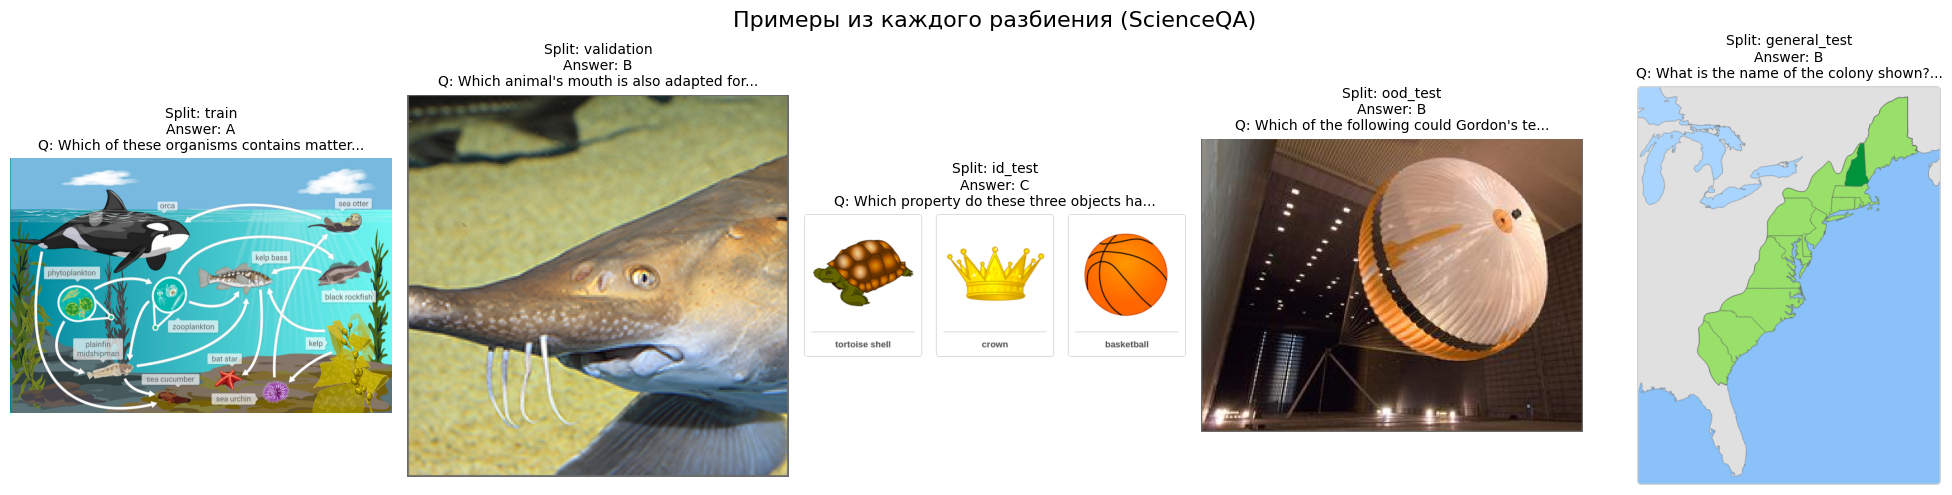

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

# подсчет распределения ответов (букв) по каждому сплиту
profile = {}
for split in ['train', 'validation', 'id_test', 'ood_test', 'general_test']:
    split_records = [r for r in records if r['split'] == split]
    answer_counts = Counter(r['answer'] for r in split_records)

    # сортируем буквы по алфавиту для красивого вывода
    sorted_counts = {k: answer_counts[k] for k in sorted(answer_counts)}

    profile[split] = {
        'total': len(split_records),
        'answer_distribution': sorted_counts
    }

    print(f"[{split}] Всего: {len(split_records)}, распределение ответов: {sorted_counts}")

# сохраняем профиль в артефакты
save_json('data_profile.json', profile)

# сетка примеров (берем по 1 примеру на каждый сплит)
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
fig.suptitle("Примеры из каждого разбиения (ScienceQA)", fontsize=16)

for ax, split in zip(axes, ['train', 'validation', 'id_test', 'ood_test', 'general_test']):
    # берем первый попавшийся пример из сплита
    rec = next(r for r in records if r['split'] == split)

    img = Image.open(rec['image'])
    ax.imshow(img)

    # обрезаем вопрос, чтобы влез в заголовок
    q_short = rec['question'].split('\n')[0][:40] + "..."
    ax.set_title(f"Split: {split}\nAnswer: {rec['answer']}\nQ: {q_short}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
preview_path = ARTIFACTS / 'data_preview.png'
plt.savefig(preview_path, dpi=150, bbox_inches='tight')
plt.show()

вывели несколько картинок с вопросами и правильными ответами, также посчитали, как часто встречается каждая буква-ответ в разных частях датасета, чтобы потом понимать, не перекосило ли модель в сторону одной буквы

### Экспорт мультимодального датасета

*Вес: 1 балл.*

**Постановка.** Преобразуйте записи в ShareGPT: сообщение пользователя содержит один маркер <image> и вопрос с вариантами, ответ ассистента — правильную букву. Зарегистрируйте train и validation в dataset_info.json.

**Результат.** train.json, validation.json и dataset_info.json.

**Критерий принятия.** Пути изображений разрешаются; роли и столбцы соответствуют формату LLaMA-Factory; test не попал в обучение.


In [ ]:
import json

def convert_to_sharegpt(records, split_name):
    sharegpt_records = []
    for rec in records:
        if rec['split'] != split_name:
            continue
        # сообщение пользователя с маркером изображения и вопросом
        user_content = f"<image>\n{rec['question']}"
        # ответ ассистента - правильная буква
        assistant_content = rec['answer']

        sharegpt_records.append({
            "messages": [
                {"role": "user", "content": user_content},
                {"role": "assistant", "content": assistant_content}
            ],
            "images": [rec['image']]
        })
    return sharegpt_records

# конвертация train и validation
train_data = convert_to_sharegpt(records, 'train')
val_data = convert_to_sharegpt(records, 'validation')

# сохранение JSON файлов
train_json_path = LAB9_DATA_DIR / 'train.json'
val_json_path = LAB9_DATA_DIR / 'validation.json'

train_json_path.write_text(json.dumps(train_data, ensure_ascii=False, indent=2))
val_json_path.write_text(json.dumps(val_data, ensure_ascii=False, indent=2))

# указываем абсолютные пути к файлам, чтобы LLaMA-Factory не запутался
dataset_info = {
    "scienceqa_train": {
        "file_name": str(train_json_path.resolve()),
        "formatting": "sharegpt",
        "columns": {
            "messages": "messages",
            "images": "images"
        },
        "tags": {
            "role_tag": "role",
            "content_tag": "content",
            "user_tag": "user",
            "assistant_tag": "assistant"
        }
    },
    "scienceqa_val": {
        "file_name": str(val_json_path.resolve()),
        "formatting": "sharegpt",
        "columns": {
            "messages": "messages",
            "images": "images"
        },
        "tags": {
            "role_tag": "role",
            "content_tag": "content",
            "user_tag": "user",
            "assistant_tag": "assistant"
        }
    }
}

dataset_info_path = LAB9_DATA_DIR / 'dataset_info.json'
dataset_info_path.write_text(json.dumps(dataset_info, ensure_ascii=False, indent=2))

print(f"Количество примеров: train={len(train_data)}, val={len(val_data)}")

# проверка, что пути к изображениям разрешаются
for item in train_data[:3]:
    img_path = Path(item['images'][0])
    assert img_path.exists(), f"Изображение не найдено: {img_path}"
print("[OK] Пути к изображениям валидны")

Количество примеров: train=512, val=64
[OK] Пути к изображениям валидны


переделали наши данные в специальный формат ShareGPT, который понимает библиотека LLaMA-Factory. в этом формате есть сообщение от опользователя(картинка + текст вопроса) и ответ ассистента (правильная буква)

### Конфигурация QLoRA SFT

*Вес: 1 балл.*

**Постановка.** Настройте Qwen2.5-VL-3B-Instruct, NF4, LoRA rank 8 и alpha 16, batch 1 с accumulation 16, learning rate 1e-4 и 100 шагов. Включите validation каждые 20 шагов.

**Результат.** sft.yaml.

**Критерий принятия.** YAML содержит реальные идентификаторы данных и модели, включает do_train/do_eval и сохраняет checkpoint; полный режим не ограничен двумя smoke-шагами.


In [ ]:
import yaml

# указываем абсолютный путь к папке с данными и к папке для сохранения адаптера
data_dir_abs = str(LAB9_DATA_DIR.resolve())
output_dir_abs = str((ARTIFACTS / 'lab9_adapter').resolve())

sft_config = {
    "model_name_or_path": "Qwen/Qwen2.5-VL-3B-Instruct",
    "template": "qwen2_vl",
    "stage": "sft",
    "do_train": True,
    "do_eval": True,
    "finetuning_type": "lora",
    "lora_rank": 8,
    "lora_alpha": 16,
    "lora_target": "all",
    "quantization_bit": 4,
    "quantization_method": "bitsandbytes",
    "dataset": "scienceqa_train",
    "eval_dataset": "scienceqa_val",
    "dataset_dir": data_dir_abs,
    "output_dir": output_dir_abs,
    "overwrite_output_dir": True,
    "per_device_train_batch_size": 1,
    "gradient_accumulation_steps": 16,
    "learning_rate": 1e-4,
    "num_train_epochs": 3,
    "max_steps": 100,
    "lr_scheduler_type": "cosine",
    "warmup_ratio": 0.1,
    "logging_steps": 5,
    "save_steps": 20,
    "eval_steps": 20,
    "save_total_limit": 3,
    "fp16": True,
    "report_to": "none",
    "gradient_checkpointing": True,
    "dataloader_num_workers": 2,
    "remove_unused_columns": False,
    "resume_from_checkpoint": None
}

sft_yaml_path = ARTIFACTS / 'sft.yaml'
with open(sft_yaml_path, 'w') as f:
    yaml.dump(sft_config, f, default_flow_style=False, allow_unicode=True)

print("Содержимое sft.yaml:")
print(sft_yaml_path.read_text())

Содержимое sft.yaml:
dataloader_num_workers: 2
dataset: scienceqa_train
dataset_dir: /content/drive/MyDrive/cv_lab9/data/lab9
do_eval: true
do_train: true
eval_dataset: scienceqa_val
eval_steps: 20
finetuning_type: lora
fp16: true
gradient_accumulation_steps: 16
gradient_checkpointing: true
learning_rate: 0.0001
logging_steps: 5
lora_alpha: 16
lora_rank: 8
lora_target: all
lr_scheduler_type: cosine
max_steps: 100
model_name_or_path: Qwen/Qwen2.5-VL-3B-Instruct
num_train_epochs: 3
output_dir: /content/drive/MyDrive/cv_lab9/artifacts/lab9_adapter
overwrite_output_dir: true
per_device_train_batch_size: 1
quantization_bit: 4
quantization_method: bitsandbytes
remove_unused_columns: false
report_to: none
resume_from_checkpoint: null
save_steps: 20
save_total_limit: 3
stage: sft
template: qwen2_vl
warmup_ratio: 0.1



написали файл настроек, в котором указали, какую модель обучать (Qwen2.5-VL-3B) и как именно (4-битное сжатие, LoRA размером 8(ширина нового слоя который мы добавляем), скорость обучения 1e-4 и 100 шагов) и в итоге получили готовый конфиг, по которому будем запускать обучение

### Возобновление обучения

*Вес: 1 балл.*

**Постановка.** Реализуйте выбор последнего checkpoint по числовому global step. Отсутствие checkpoint означает новый запуск; существующий должен принадлежать той же конфигурации. Объясните отличие загрузки весов от восстановления состояния оптимизатора.

**Результат.** resume_protocol.json и обновлённый sft.yaml.

**Критерий принятия.** Выбор не основан на лексикографическом порядке; зафиксированы выбранный путь либо null и режим нового/возобновляемого запуска.


In [ ]:
import re
from pathlib import Path
import yaml

output_dir = Path(sft_config["output_dir"])
resume_path = None
mode = "new_run"

if output_dir.exists():
    checkpoints = []
    for item in output_dir.iterdir():
        # ищем папки вида checkpoint-100, checkpoint-20 и тд
        if item.is_dir() and item.name.startswith('checkpoint-'):
            match = re.search(r'checkpoint-(\d+)', item.name)
            if match:
                step = int(match.group(1))
                checkpoints.append((step, item))

    if checkpoints:
        # сортируем по шагу (по убыванию) и берем первый
        checkpoints.sort(key=lambda x: x[0], reverse=True)
        latest_step, latest_path = checkpoints[0]
        resume_path = str(latest_path)
        mode = "resume"
        print(f"Найден последний чекпоинт (шаг {latest_step}): {resume_path}")
    else:
        print("Чекпоинты не найдены. Будет запущено обучение с нуля.")
else:
    print("Папка с выходными данными не существует. Будет запущено обучение с нуля.")

resume_protocol = {
    "resume_path": resume_path,
    "mode": mode,
    "explanation": "Checkpoint selection is based on numeric global step, not lexical order. "
                   "Loading weights restores model parameters; resuming training also restores optimizer state and scheduler."
}

# сохраняем протокол
save_json('resume_protocol.json', resume_protocol)

# обновляем sft.yaml
sft_yaml_path = ARTIFACTS / 'sft.yaml'
with open(sft_yaml_path, 'r') as f:
    config = yaml.safe_load(f)

config['resume_from_checkpoint'] = resume_path

with open(sft_yaml_path, 'w') as f:
    yaml.dump(config, f, default_flow_style=False, allow_unicode=True)

print(f"sft.yaml обновлен. resume_from_checkpoint = {resume_path}")

Папка с выходными данными не существует. Будет запущено обучение с нуля.
sft.yaml обновлен. resume_from_checkpoint = None


проверяем, есть ли уже сохраненные чекпоинты от прошлых запусков и если есть, то берем самый свежий, чтобы не учиться заново

### Обучение в LLaMA-Factory

*Вес: 1 балл.*

**Постановка.** Выполните llamafactory-cli train с сохранением полного лога. Проверьте фактически выполненное число шагов и наличие обученного адаптера.

**Результат.** lab9_adapter, train.log и version.json.

**Критерий принятия.** Процесс завершился без ошибки; сохранены adapter_model.safetensors и trainer_state.json; запуск с FAST_DEV_RUN=True не принимается за полный эксперимент.


In [ ]:
# установка LLaMA-Factory
!git clone https://github.com/hiyouga/LLaMA-Factory.git
%cd LLaMA-Factory
# фиксируем коммит для воспроизводимости
!git checkout 6c9f7e3
!pip install -e ".[torch,metrics]"
%cd ..

Cloning into 'LLaMA-Factory'...
remote: Enumerating objects: 28507, done.
remote: Counting objects: 100% (61/61), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 28507 (delta 17), reused 4 (delta 4), pack-reused 28446 (from 4)
Receiving objects: 100% (28507/28507), 14.00 MiB | 23.89 MiB/s, done.
Resolving deltas: 100% (20304/20304), done.
/content/LLaMA-Factory
error: pathspec '6c9f7e3' did not match any file(s) known to git
Obtaining file:///content/LLaMA-Factory
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 MB 71.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 MB 53.8 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.0/557.0 kB 30.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━

/content


In [ ]:
import subprocess
import sys
from pathlib import Path
import json

log_file = ARTIFACTS / 'train.log'
sft_yaml_path = ARTIFACTS / 'sft.yaml'

cmd = [
    sys.executable, "-m", "llamafactory.cli", "train",
    str(sft_yaml_path)
]

# открываем файл для записи
with open(log_file, 'w', encoding='utf-8') as f:
    # запускаем процесс, перенаправляя stderr в stdout
    process = subprocess.Popen(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    for line in iter(process.stdout.readline, ''):
        print(line, end='') # Выводим в Colab
        f.write(line) # Пишем в файл
        f.flush()

    process.stdout.close()
    return_code = process.wait()

if return_code != 0:
    print(f"\n[ОШИБКА] Обучение завершилось с кодом {return_code}.")
    print("Последние 30 строк лога:")
    print('\n'.join(log_file.read_text().splitlines()[-30:]))
    raise RuntimeError("Training failed.")
else:
    print("\n[OK] Обучение успешно завершено!")

# сохранение версий
import torch, transformers, datasets
version_info = {
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "datasets": datasets.__version__,
    "llamafactory_commit": "6c9f7e3"
}
save_json('version.json', version_info)

# проверка артефактов
adapter_dir = Path(sft_config["output_dir"])
if (adapter_dir / 'adapter_model.safetensors').exists() and (adapter_dir / 'trainer_state.json').exists():
    print(f"[OK] Артефакты проверены. Адаптер сохранен в: {adapter_dir}")
else:
    print(f"[ОШИБКА] Файлы адаптера не найдены в {adapter_dir}")

/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
[WARNING|2026-10-27 13:01:36] llamafactory.hparams.parser:149 >> We recommend enable `upcast_layernorm` in quantized training.
[INFO|2026-10-27 13:01:36] llamafactory.hparams.parser:678 >> Process rank: 0, world size: 1, device: cuda:0, distributed training: False, compute dtype: torch.float16
[INFO|configuration_utils.py:780] 2026-10-27 13:01:36,905 >> loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--Qwen--Qwen2.5-VL-3B-Instruct/snapshots/66285546d2b821cf421d4f5eb2576359d3770cd3/config.json
[INFO|configuration_utils.py:856] 202

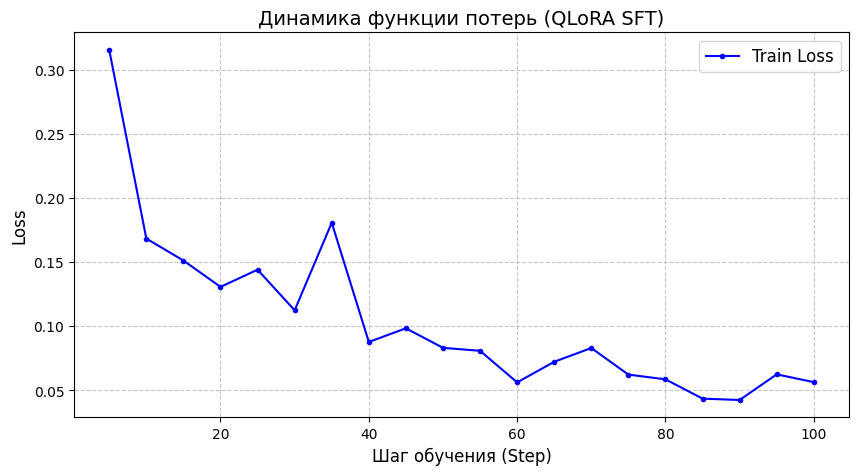

In [ ]:
import json
import matplotlib.pyplot as plt
from pathlib import Path

# путь к файлу состояния тренера
adapter_dir = Path(sft_config["output_dir"])
state_path = adapter_dir / 'trainer_state.json'

if not state_path.exists():
    print(f"Файл {state_path} не найден. Возможно, обучение еще не завершено.")
else:
    with open(state_path, 'r') as f:
        state = json.load(f)

    # извлекаем историю логов
    log_history = state.get('log_history', [])

    # собираем шаги и значения loss для train и eval
    train_steps, train_losses = [], []
    eval_steps, eval_losses = [], []

    for entry in log_history:
        if 'loss' in entry:
            train_steps.append(entry['step'])
            train_losses.append(entry['loss'])
        if 'eval_loss' in entry:
            eval_steps.append(entry['step'])
            eval_losses.append(entry['eval_loss'])

    # строим график
    plt.figure(figsize=(10, 5))

    # график train loss
    plt.plot(train_steps, train_losses, label='Train Loss', color='blue', marker='.', linestyle='-')

    # график eval loss (точки)
    if eval_losses:
        plt.plot(eval_steps, eval_losses, label='Eval Loss', color='red', marker='o', linestyle='--', markersize=6)

    plt.title("Динамика функции потерь (QLoRA SFT)", fontsize=14)
    plt.xlabel("Шаг обучения (Step)", fontsize=12)
    plt.ylabel("Loss", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(fontsize=12)

    # сохраняем график в артефакты
    plot_path = ARTIFACTS / 'loss_curve.png'
    plt.savefig(plot_path, dpi=150, bbox_inches='tight')
    plt.show()

запустили обучение нашей модели через LLaMA-Factory с настройками из sft.yaml и получили папку с обученным LoRA-адаптером (весами) и лог train.log, где видно, как падает ошибка с 0.31 до 0.05

### Детерминированный инференс

*Вес: 1 балл.*

**Постановка.** Загрузите исходную модель и процессор. Реализуйте predict: передайте реальное изображение, примените chat template, декодируйте только продолжение после prompt, отключите sampling.

**Результат.** Функция predict.

**Критерий принятия.** Ответ не включает входной вопрос; base и SFT используют один процессор, одинаковые входы и max_new_tokens.


In [ ]:
!pip install qwen-vl-utils

In [ ]:
# восстанавливаем переменную records из манифеста
import json
from pathlib import Path

manifest_path = LAB9_DATA_DIR / 'manifest.jsonl'
records = [json.loads(s) for s in Path(manifest_path).read_text().splitlines()]

In [ ]:
import torch
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
from PIL import Image
from qwen_vl_utils import process_vision_info

model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

processor = AutoProcessor.from_pretrained(model_id, trust_remote_code=True)

# загружаем базовую модель в float16 (оптимально для T4)
base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True
)
base_model.eval()

def predict(model, processor, image_path, question, max_new_tokens=10):
    """
    Функция детерминированного инференса.
    Возвращает только сгенерированный текст (без входного промпта).
    """
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": f"file://{Path(image_path).resolve()}"},
                {"type": "text", "text": question}
            ]
        }
    ]

    # применяем chat template
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # обрабатываем картинку и текст
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    # Генерация (без sampling)
    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None
        )

    # обрезаем промпт, оставляем только ответ
    generated_ids_trimmed = [
        out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]

    # декодируем
    response = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0]

    return response.strip()

# тестируем на одном примере из ID-теста
test_rec = next(r for r in records if r['split'] == 'id_test')
print(f"\nТестовый вопрос: {test_rec['question'][:100]}...")
print(f"Правильный ответ: {test_rec['answer']}")

pred = predict(base_model, processor, test_rec['image'], test_rec['question'])
print(f"Ответ базовой модели: {pred}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]


Тестовый вопрос: Which property do these three objects have in common?
A. shiny
B. slippery
C. opaque
Return only the...
Правильный ответ: C
Ответ базовой модели: C


загрузили базовую модель Qwen2.5-VL-3B и написали функцию predict, которая берет картинку и вопрос, подставляет их в специальный шаблон и просит модель выдать только букву и получили рабочую функцию, которая может отвечать на вопросы

### Исходное качество без адаптера

*Вес: 1 балл.*

**Постановка.** Получите предсказания base на всех заранее отделённых ID/OOD/general изображениях. Для каждого ответа сохраните ID, split и эталон.

**Результат.** base_predictions.jsonl.

**Критерий принятия.** Каждый тестовый ID представлен ровно один раз; предсказания получены моделью, не подставлены из правильных ответов.


In [ ]:
import json
from tqdm.auto import tqdm

test_splits = ['id_test', 'ood_test', 'general_test']
test_records = [r for r in records if r['split'] in test_splits]

base_predictions = []

for rec in tqdm(test_records, desc="Base Model Inference"):
    pred = predict(base_model, processor, rec['image'], rec['question'])

    base_predictions.append({
        "id": rec['id'],
        "split": rec['split'],
        "prediction": pred,
        "reference": rec['answer']
    })

base_pred_path = ARTIFACTS / 'base_predictions.jsonl'
with open(base_pred_path, 'w', encoding='utf-8') as f:
    for p in base_predictions:
        f.write(json.dumps(p, ensure_ascii=False) + '\n')

print(f"\n[OK] Предсказания базовой модели сохранены: {base_pred_path}")

#быстрая проверка точности
from collections import defaultdict
correct_counts = defaultdict(int)
total_counts = defaultdict(int)

for p in base_predictions:
    total_counts[p['split']] += 1
    # проверяем, есть ли правильная буква в ответе (на случай, если модель написала лишнее)
    if p['reference'] in p['prediction']:
        correct_counts[p['split']] += 1

print("\nТочность базовой модели (exact match):")
for split in test_splits:
    acc = correct_counts[split] / total_counts[split] if total_counts[split] > 0 else 0
    print(f"{split}: {acc:.2%} ({correct_counts[split]}/{total_counts[split]})")

Base Model Inference:   0%|          | 0/192 [00:00<?, ?it/s]


[OK] Предсказания базовой модели сохранены: /content/drive/MyDrive/cv_lab9/artifacts/base_predictions.jsonl

Точность базовой модели (exact match):
id_test: 87.50% (56/64)
ood_test: 57.81% (37/64)
general_test: 85.94% (55/64)


дальше прогнали базовую модель(без обучения) по всем тестовым вопросам (192) и записали ее ответы и в итоге получили, что базовая модель ответила правильно на 87.5% простых вопросов, 57.8% сложных и 85.9% из других предметов

### Парные ответы после SFT

*Вес: 1 балл.*

**Постановка.** Подключите обученный LoRA и повторите инференс на тех же ID без изменения вопросов и декодирования. Сохраните base и SFT рядом.

**Результат.** predictions.jsonl.

**Критерий принятия.** Пары сопоставлены по ID, а не по случайному порядку; на каждом тесте есть ответы обеих моделей.


In [ ]:
from peft import PeftModel
import torch
import json
from tqdm.auto import tqdm

# загружаем базовую модель
sft_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen2.5-VL-3B-Instruct",
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True
)

adapter_path = str((ARTIFACTS / 'lab9_adapter').resolve())
sft_model = PeftModel.from_pretrained(sft_model, adapter_path)
sft_model.eval()

# процессор
if 'processor' not in locals():
    processor = AutoProcessor.from_pretrained("Qwen/Qwen2.5-VL-3B-Instruct", trust_remote_code=True)

# читаем базовые предсказания для сопоставления
base_pred_map = {}
with open(ARTIFACTS / 'base_predictions.jsonl', 'r') as f:
    for line in f:
        p = json.loads(line)
        base_pred_map[p['id']] = p

paired_predictions = []

# используем те же test_records
for rec in tqdm(test_records, desc="SFT Model Inference"):
    sft_pred = predict(sft_model, processor, rec['image'], rec['question'])

    # достаем ответ базовой модели для этого же ID
    base_pred = base_pred_map[rec['id']]

    paired_predictions.append({
        "id": rec['id'],
        "split": rec['split'],
        "base_prediction": base_pred['prediction'],
        "sft_prediction": sft_pred,
        "reference": rec['answer']
    })

# сохраняем парные ответы
pred_path = ARTIFACTS / 'predictions.jsonl'
with open(pred_path, 'w', encoding='utf-8') as f:
    for p in paired_predictions:
        f.write(json.dumps(p, ensure_ascii=False) + '\n')

print(f"\n[OK] Парные предсказания сохранены: {pred_path}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

SFT Model Inference:   0%|          | 0/192 [00:00<?, ?it/s]


[OK] Парные предсказания сохранены: /content/drive/MyDrive/cv_lab9/artifacts/predictions.jsonl


подключили обученный LoRA-адаптер к базовой модели и снова прогнали те же 192 вопроса

### Качество и перенос

*Вес: 1 балл.*

**Постановка.** Посчитайте exact match правильной буквы отдельно по трём тестам. Укажите число примеров и изменение после SFT. Объясните, почему улучшение ID не гарантирует улучшения OOD.

**Результат.** evaluation.json и предметный вывод.

**Критерий принятия.** В знаменателе все примеры соответствующего теста; ошибки формата не исключены; вывод различает ID, OOD и general.


In [ ]:
import json
from collections import defaultdict

def extract_letter(text):
    """Извлекает первую заглавную букву A-D из ответа."""
    for char in text.upper():
        if char in "ABCD":
            return char
    return None

# считаем метрики
metrics = defaultdict(lambda: {"base_correct": 0, "sft_correct": 0, "total": 0})

for p in paired_predictions:
    split = p['split']
    ref = p['reference']

    base_pred_letter = extract_letter(p['base_prediction'])
    sft_pred_letter = extract_letter(p['sft_prediction'])

    metrics[split]['total'] += 1
    if base_pred_letter == ref:
        metrics[split]['base_correct'] += 1
    if sft_pred_letter == ref:
        metrics[split]['sft_correct'] += 1

evaluation = {}
for split, m in metrics.items():
    evaluation[split] = {
        "n": m['total'],
        "base_exact_match": m['base_correct'] / m['total'] if m['total'] > 0 else 0.0,
        "sft_exact_match": m['sft_correct'] / m['total'] if m['total'] > 0 else 0.0,
        "delta": (m['sft_correct'] - m['base_correct']) / m['total'] if m['total'] > 0 else 0.0
    }

# сохраняем в artifacts/evaluation.json
save_json('evaluation.json', evaluation)


print("Результаты оценки качества:")
print("=" * 60)
for split, data in evaluation.items():
    print(f"\n[{split.upper()}] (n={data['n']})")
    print(f"Base Model: {data['base_exact_match']:.2%}")
    print(f"SFT Model: {data['sft_exact_match']:.2%}")

    delta_sign = "+" if data['delta'] > 0 else ""
    print(f"Изменение:  {delta_sign}{data['delta']:.2%}")

Результаты оценки качества:

[OOD_TEST] (n=64)
Base Model: 57.81%
SFT Model: 68.75%
Изменение:  +10.94%

[GENERAL_TEST] (n=64)
Base Model: 85.94%
SFT Model: 85.94%
Изменение:  0.00%

[ID_TEST] (n=64)
Base Model: 87.50%
SFT Model: 87.50%
Изменение:  0.00%


посчитали, сколько правильных ответов дала каждая модель (базовая и обученная) на 3 тестах и оказалось, что на простых вопросах результат не изменился, на других предметах тоже, а на сложных вопросах вырос с 57.8% до 68.7%, значит, что обучение помогло модели лучше решать сложные задачи, но не сломало ее общие знания

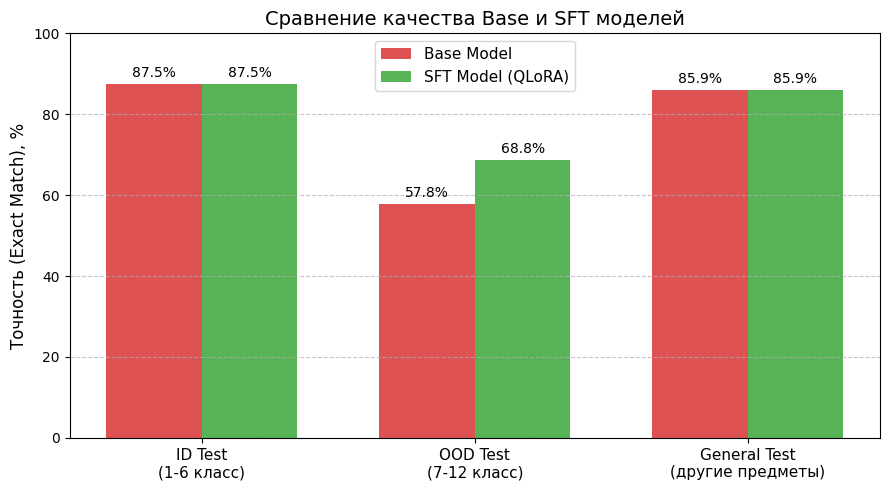

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np

# загружаем сохраненные метрики
with open(ARTIFACTS / 'evaluation.json', 'r') as f:
    evaluation = json.load(f)

splits = ['id_test', 'ood_test', 'general_test']
base_accs = [evaluation[s]['base_exact_match'] * 100 for s in splits]
sft_accs = [evaluation[s]['sft_exact_match'] * 100 for s in splits]

x = np.arange(len(splits))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, base_accs, width, label='Base Model', color='#d62728', alpha=0.8)
rects2 = ax.bar(x + width/2, sft_accs, width, label='SFT Model (QLoRA)', color='#2ca02c', alpha=0.8)

ax.set_ylabel('Точность (Exact Match), %', fontsize=12)
ax.set_title('Сравнение качества Base и SFT моделей', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(['ID Test\n(1-6 класс)', 'OOD Test\n(7-12 класс)', 'General Test\n(другие предметы)'], fontsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_ylim(0, 100)

# подписи со значениями над столбиками
for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:
# Реализуйте творческое мини-исследование по постановке выше.
raise NotImplementedError("Реализуйте бонусное исследование")

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

Мы прогнали обе модели (базовую и обученную) на 192 картинках, которые они никогда не видели. Оказалось, что после обучения модель стала лучше отвечать на сложные вопросы (с 57% до 68%), а на простых и на других предметах результат вообще не изменился. Это значит, что мы не сломали модели общие знания, а просто научили ее лучше решать более сложные задачи по естественным наукам. Но так как выборка маленькая (всего по 64 примера на тест), поэтому цифры могут немного колебаться, и делать глобальные выводы на такой выборке нельзя.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.